# Hyperparameter Sensitivity

2x2 contour grid from the full hyperparameter sweep
(`ablation/full_hyperparameter_sweep.yml`).

|  | Latent dim. $d$ | Triplet Margin $\alpha$ |
|---|---|---|
| **MI reg. $\lambda_{\mathrm{MI}}$** | $d$ vs $\lambda_{\mathrm{MI}}$ | $\alpha$ vs $\lambda_{\mathrm{MI}}$ |
| **Frobenius reg. $\lambda_F$** | $d$ vs $\lambda_F$ | $\alpha$ vs $\lambda_F$ |

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import yaml

import ggml_ot
from ggml_ot.plot.contour import _dict_to_grid

# Same matplotlib settings as the pipeline (TrueType fonts in PDFs, see snakemake/config/matplotlibrc)
matplotlib.rc_file("../snakemake/config/matplotlibrc", use_default_template=False)

sys.path.insert(0, str(Path("../snakemake/scripts").resolve()))
from _utils import (
    get_gmm_key,
    get_dataset_construction_params,
    get_method_tune_kwargs,
    get_tune_hash,
    apply_runtime_settings,
)

In [2]:
dataset_name = "myocardial_infarction"
method_name = "GMM_DiagBures"
config_file = "config/ablation/full_hyperparameter_sweep.yml"

# Override specific best params (e.g. fix latent dim to 5 which performs very closely to 2 dims, but provides less unique itnerpretable axis)
best_override = {}

# Optional preference to break ties among equally best configurations.
# The representative `best` will be chosen from the tied best rows by maximising
# the number of matching parameter values here. "benchmark" prefers the configuration
# the main benchmark selected for this dataset/method (its best_params.json), so the
# x marks the benchmark params whenever they are among the tied best.
tie_breaker_preference = "benchmark"
benchmark_config_file = "config/paper/main_benchmark.yml"

include_title = True

# Set to a previous tune hash to bypass config-derived hash (e.g. while a new sweep is running)
tune_hash_override = None #"6183e548"  # previous sweep run

snakemake_dir = Path("../snakemake").resolve()

def deep_merge(base, override):
    """Recursive dict merge (mimics Snakemake's configfile merging)."""
    result = dict(base)
    for k, v in override.items():
        if k in result and isinstance(result[k], dict) and isinstance(v, dict):
            result[k] = deep_merge(result[k], v)
        else:
            result[k] = v
    return result

def load_config(config_file):
    with open(snakemake_dir / "config/defaults.yml") as f:
        config = yaml.safe_load(f)
    with open(snakemake_dir / config_file) as f:
        config = deep_merge(config, yaml.safe_load(f))
    with open(snakemake_dir / "config" / config["datasets_file"]) as f:
        config["datasets"] = yaml.safe_load(f)["datasets"]
    return config

def get_tune_dir(config):
    """Tune results directory of dataset_name/method_name as derived by the pipeline."""
    ds_meta = config["datasets"][dataset_name]
    gmm_key = get_gmm_key(config, ds_meta)
    ds_params = get_dataset_construction_params(config, ds_meta, config["methods"][method_name], gmm_key)
    tune_h = get_tune_hash(method_name, get_method_tune_kwargs(config, method_name), ds_params)
    return (snakemake_dir / config["data_root"]).resolve() / dataset_name / "tune" / method_name / tune_h

config = load_config(config_file)
apply_runtime_settings(config)

# Derive tune results path
tune_dir = get_tune_dir(config)
if tune_hash_override:
    tune_dir = tune_dir.parent / tune_hash_override
tune_h = tune_dir.name

scores_path = tune_dir / "scores.csv"
assert scores_path.exists(), f"Tune results not found: {scores_path}"

sweep_df = pd.read_csv(scores_path, header=[0, 1], index_col=[0, 1, 2, 3, 4])

with open(scores_path.parent / "best_params.json") as f:
    best = json.load(f)

if tie_breaker_preference == "benchmark":
    benchmark_best_path = get_tune_dir(load_config(benchmark_config_file)) / "best_params.json"
    assert benchmark_best_path.exists(), f"Benchmark tune results not found: {benchmark_best_path}"
    with open(benchmark_best_path) as f:
        tie_breaker_preference = json.load(f)
    print(f"Benchmark params ({benchmark_best_path.parent.name}): {tie_breaker_preference}")

value_col = ("knn", "mean")
flat_col_val = " ".join(value_col).strip()
index_names = list(sweep_df.index.names)

# If overrides or tie-break preferences are given, derive the representative best
# directly from the sweep rather than trusting the stored best_params.json.
if best_override or tie_breaker_preference:
    if best_override:
        index_slice = pd.IndexSlice[tuple(best_override.get(name, slice(None)) for name in index_names)]
        candidate_scores = sweep_df.loc[index_slice, value_col].reset_index()
    else:
        candidate_scores = sweep_df.loc[:, value_col].reset_index()
    candidate_scores.columns = [*index_names, flat_col_val]
    assert not candidate_scores.empty, f"No configs match best_override={best_override}"
    best_knn = candidate_scores[flat_col_val].max()
    best_rows = candidate_scores.loc[np.isclose(candidate_scores[flat_col_val], best_knn), [flat_col_val, *index_names]].copy()
else:
    best_knn = sweep_df.loc[pd.IndexSlice[tuple(best[name] for name in index_names)], value_col]
    best_rows = pd.DataFrame([[best_knn, *(best[name] for name in index_names)]], columns=[flat_col_val, *index_names])

if tie_breaker_preference:
    best_rows["tie_break_matches"] = best_rows.apply(
        lambda row: sum(
            (row[name] == pref) if isinstance(pref, str) else bool(np.isclose(row[name], pref))
            for name, pref in tie_breaker_preference.items()
            if name in index_names
        ),
        axis=1,
    )
    best_rows = best_rows.sort_values(["tie_break_matches", *index_names], ascending=[False] + [True] * len(index_names)).reset_index(drop=True)
    n_prefs = sum(name in index_names for name in tie_breaker_preference)
    if best_rows.loc[0, "tie_break_matches"] < n_prefs:
        print(f"WARNING: preferred params {tie_breaker_preference} are not among the tied best; x marks the closest tied config")
else:
    best_rows = best_rows.sort_values(index_names).reset_index(drop=True)

best = best_rows.loc[0, index_names].to_dict()

best_table = best_rows.rename(columns={flat_col_val: "knn acc", "n_comps": "n_Comps"})[["knn acc", "n_Comps", "reg_type", "alpha", "reg", "mi_reg"]]

print(f"Tune hash: {tune_h}" + (" (override)" if tune_hash_override else ""))
print(f"Sweep: {sweep_df.shape[0]} configs")
if tie_breaker_preference:
    print(f"Tie-breaker preference: {tie_breaker_preference}")
print(f"Best{' (conditioned on overrides)' if best_override else ''}: {best}")
print(f"Best k-NN acc{' (conditioned on overrides)' if best_override else ''}: {best_knn}")
print(f"Best combinations{' (conditioned on overrides)' if best_override else ''}:")
print(best_table.to_string(index=False))
for name in sweep_df.index.names:
    if name is not None:
        vals = sorted(sweep_df.index.get_level_values(name).unique())
        print(f"  {name}: {vals}")

Benchmark params (faecda83): {'alpha': 1, 'mi_reg': 0.0001, 'n_comps': 5, 'reg': 0.0001, 'reg_type': 'fro'}
Tune hash: 1674ddcf
Sweep: 540 configs
Tie-breaker preference: {'alpha': 1, 'mi_reg': 0.0001, 'n_comps': 5, 'reg': 0.0001, 'reg_type': 'fro'}
Best: {'n_comps': 5, 'reg_type': 'fro', 'alpha': 1.0, 'reg': 0.0001, 'mi_reg': 0.0001}
Best k-NN acc: 0.9444444444444444
Best combinations:
 knn acc  n_Comps reg_type  alpha     reg  mi_reg
0.944444        5      fro    1.0  0.0001  0.0001
0.944444        2      fro    1.0  0.0001  0.0001
0.944444        5      fro    1.0  0.0001 10.0000
0.944444        5      fro    1.0  0.0100  0.0001
0.944444       10      fro    1.0  0.0001  0.0001
0.944444        2      fro    0.1  0.0001  0.0001
0.944444        2      fro    1.0  0.0001  1.0000
0.944444        2      fro    1.0  1.0000  0.0001
0.944444        5      fro    0.1  0.0001  0.0100
0.944444        5      fro    0.1  0.0001  0.1000
0.944444        5      fro    1.0  0.0010  0.0010
0.944444  

Saved: ../data/generated_plots/hyperparameter_sensitivity/contour_2x2_hyperparameter_sensitivity.pdf


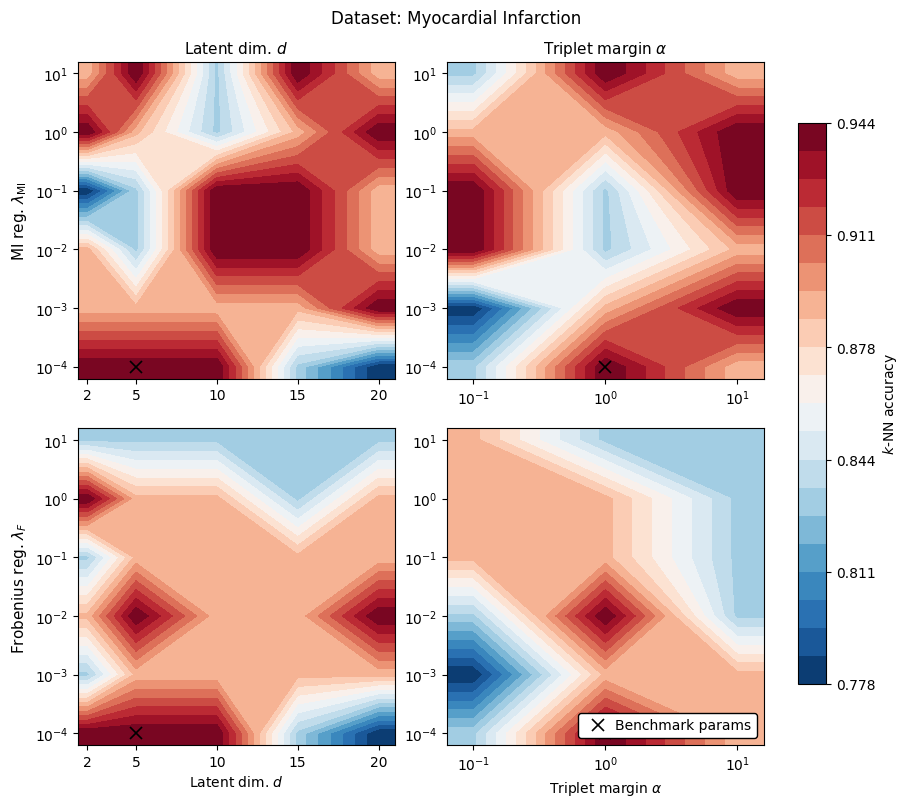

In [3]:
value_col = ("knn", "mean")

# Pretty names for annotation
param_labels = {
    "alpha": r"$\alpha$",
    "reg": r"$\lambda_F$",
    "mi_reg": r"$\lambda_{\mathrm{MI}}$",
    "n_comps": r"$d$",
}

# Transposed layout:
#              Latent dim. d          Triplet Margin α
#   λ_MI     n_comps vs mi_reg       alpha vs mi_reg
#   λ_F      n_comps vs reg          alpha vs reg
panels = [
    ("n_comps", "mi_reg",  {"alpha": best["alpha"], "reg_type": "fro", "reg": best.get("reg")}),
    ("alpha",   "mi_reg",  {"n_comps": best["n_comps"], "reg_type": "fro", "reg": best.get("reg")}),
    ("n_comps", "reg",     {"alpha": best["alpha"], "reg_type": "fro", "mi_reg": best.get("mi_reg")}),
    ("alpha",   "reg",     {"n_comps": best["n_comps"], "reg_type": "fro", "mi_reg": best.get("mi_reg")}),
]

col_labels = [r"Latent dim. $d$", r"Triplet margin $\alpha$"]
row_labels = [r"MI reg. $\lambda_{\mathrm{MI}}$", r"Frobenius reg. $\lambda_F$"]

# Build the "x best" subtitle once
best_str = ", ".join(f"{param_labels[k]}={best[k]}" for k in ["n_comps", "alpha", "reg", "mi_reg"])

# Pre-compute all grids to find shared colormap range
grids = []
for x_param, y_param, fixed in panels:
    grid = _dict_to_grid(sweep_df, x=x_param, y=y_param, fixed_params=fixed, col_val=value_col)
    grids.append(grid)

vmin = min(g.to_numpy().min() for g in grids)
vmax = max(g.to_numpy().max() for g in grids)
shared_levels = np.linspace(vmin, vmax, 21)
colorbar_ticks = np.linspace(vmin, vmax, 6)
benchmark_handle = Line2D([0], [0], marker="x", linestyle="None", color="black", markersize=8, markeredgewidth=1.2, label="Benchmark params")

def _pad_axis_for_contour(values, use_log, pad_fraction=0.2):
    coords = np.log10(values) if use_log else np.asarray(values, dtype=float)
    if len(coords) > 1:
        left_step = coords[1] - coords[0]
        right_step = coords[-1] - coords[-2]
    else:
        left_step = right_step = 1.0
    return np.pad(
        coords,
        (1, 1),
        "constant",
        constant_values=(coords[0] - pad_fraction * left_step, coords[-1] + pad_fraction * right_step),
    )

fig, axes = plt.subplots(2, 2, figsize=(9, 8), constrained_layout=True)

for idx, (x_param, y_param, fixed) in enumerate(panels):
    row, col = divmod(idx, 2)
    ax = axes[row, col]

    grid = grids[idx]
    X = np.asarray(grid.columns, dtype=float)
    Y = np.asarray(grid.index, dtype=float)
    Z = grid.to_numpy()

    # Log-scale for regularization params and alpha; linear for n_comps
    x_log = x_param in {"reg", "mi_reg", "alpha"}
    y_log = y_param in {"reg", "mi_reg", "alpha"}

    # Pad in plot coordinates so log-scaled axes get visible border space too.
    Xp = _pad_axis_for_contour(X, x_log)
    Yp = _pad_axis_for_contour(Y, y_log)
    Z_pad = np.pad(Z, ((1, 1), (1, 1)), "edge")

    cntr = ax.contourf(Xp, Yp, Z_pad, levels=shared_levels, cmap="RdBu_r", corner_mask=True)

    ax.set_xticks(np.log10(X) if x_log else X)
    ax.set_yticks(np.log10(Y) if y_log else Y)

    fmt_log = ticker.FuncFormatter(lambda v, _: r"$10^{{{:g}}}$".format(v))
    if x_log:
        ax.xaxis.set_major_formatter(fmt_log)
    if y_log:
        ax.yaxis.set_major_formatter(fmt_log)

    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)

    # Mark best params with a slim x (matching \times in subtitle)
    best_x = best.get(x_param)
    best_y = best.get(y_param)
    if best_x is not None and best_y is not None:
        bx = np.log10(best_x) if x_log else best_x
        by = np.log10(best_y) if y_log else best_y
        ax.plot(bx, by, "x", color="black", markersize=8, markeredgewidth=1.2, zorder=5, clip_on=False)

    # Column headers on top row
    if row == 0:
        ax.set_title(col_labels[col], fontsize=11)
    # Row labels on left column
    if col == 0:
        ax.set_ylabel(row_labels[row], fontsize=11)
    else:
        ax.set_ylabel("")
    # X-axis label only on bottom row
    if row == 1:
        ax.set_xlabel(col_labels[col], fontsize=10)
    else:
        ax.set_xlabel("")

fig.colorbar(cntr, ax=axes, label="$k$-NN accuracy", shrink=0.8, ticks=colorbar_ticks, format="%.3f")
axes[1, 1].legend(handles=[benchmark_handle], loc="lower right", frameon=True, facecolor="white", edgecolor="black", framealpha=1.0, handletextpad=0.25)
if include_title:
    fig.suptitle(
        f"Dataset: {dataset_name.replace('_', ' ').title()}",
        fontsize=12,
    )

save_dir = Path("../data/generated_plots/hyperparameter_sensitivity")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "contour_2x2_hyperparameter_sensitivity.pdf", bbox_inches="tight", dpi=300)
print(f"Saved: {save_dir / 'contour_2x2_hyperparameter_sensitivity.pdf'}")
plt.show()

Saved: ../data/generated_plots/hyperparameter_sensitivity/contour_1x3_mi_reg_sensitivity.pdf


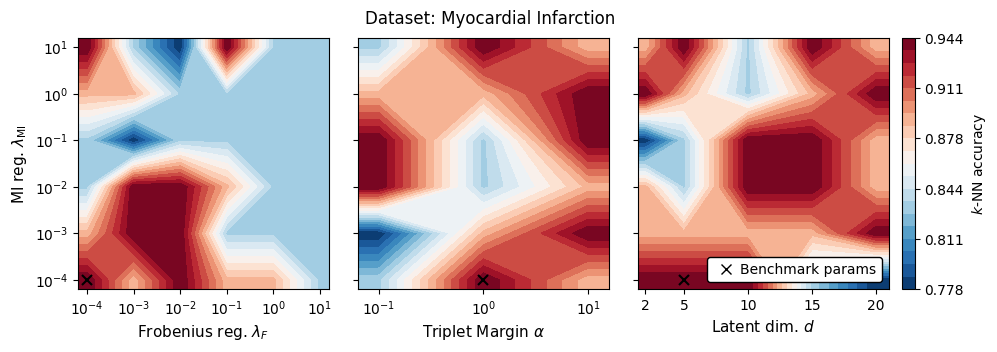

In [4]:
# 1x3 panel: MI reg. λ_MI vs each of the other three hyperparameters
panels_1x3 = [
    ("reg",     "mi_reg", {"n_comps": best["n_comps"], "alpha": best["alpha"], "reg_type": "fro"}),
    ("alpha",   "mi_reg", {"n_comps": best["n_comps"], "reg": best["reg"],     "reg_type": "fro"}),
    ("n_comps", "mi_reg", {"alpha": best["alpha"],     "reg": best["reg"],     "reg_type": "fro"}),
]
x_labels_1x3 = [r"Frobenius reg. $\lambda_F$", r"Triplet Margin $\alpha$", r"Latent dim. $d$"]

# Pre-compute grids and shared colormap range
grids_1x3 = []
for x_param, y_param, fixed in panels_1x3:
    grid = _dict_to_grid(sweep_df, x=x_param, y=y_param, fixed_params=fixed, col_val=value_col)
    grids_1x3.append(grid)

vmin_1x3 = min(g.to_numpy().min() for g in grids_1x3)
vmax_1x3 = max(g.to_numpy().max() for g in grids_1x3)
levels_1x3 = np.linspace(vmin_1x3, vmax_1x3, 21)
colorbar_ticks_1x3 = np.linspace(vmin_1x3, vmax_1x3, 6)
benchmark_handle = Line2D([0], [0], marker="x", linestyle="None", color="black", markersize=7, markeredgewidth=1.0, label="Benchmark params")

fig = plt.figure(figsize=(11, 3.8))
# Use GridSpec with tight wspace; reserve narrow column for colorbar
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.15)
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
cax = fig.add_subplot(gs[0, 3])

for idx, (x_param, y_param, fixed) in enumerate(panels_1x3):
    ax = axes[idx]
    grid = grids_1x3[idx]
    X = np.asarray(grid.columns, dtype=float)
    Y = np.asarray(grid.index, dtype=float)
    Z = grid.to_numpy()

    x_log = x_param in {"reg", "mi_reg", "alpha"}
    y_log = y_param in {"reg", "mi_reg", "alpha"}

    Xp = _pad_axis_for_contour(X, x_log)
    Yp = _pad_axis_for_contour(Y, y_log)
    Z_pad = np.pad(Z, ((1, 1), (1, 1)), "edge")

    cntr = ax.contourf(Xp, Yp, Z_pad, levels=levels_1x3, cmap="RdBu_r", corner_mask=True)

    ax.set_xticks(np.log10(X) if x_log else X)
    ax.set_yticks(np.log10(Y) if y_log else Y)

    fmt_log = ticker.FuncFormatter(lambda v, _: r"$10^{{{:g}}}$".format(v))
    if x_log:
        ax.xaxis.set_major_formatter(fmt_log)
    if y_log:
        ax.yaxis.set_major_formatter(fmt_log)

    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)

    # Mark best params
    best_x = best.get(x_param)
    best_y = best.get(y_param)
    if best_x is not None and best_y is not None:
        bx = np.log10(best_x) if x_log else best_x
        by = np.log10(best_y) if y_log else best_y
        ax.plot(bx, by, "x", color="black", markersize=7, markeredgewidth=1.5, zorder=5, clip_on=False)

    ax.set_xlabel(x_labels_1x3[idx], fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"MI reg. $\lambda_{\mathrm{MI}}$", fontsize=11)
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", labelleft=False)

cbar = fig.colorbar(cntr, cax=cax, label="$k$-NN accuracy", ticks=colorbar_ticks_1x3, format="%.3f")
ref_pos = axes[0].get_position()
right_pos = axes[-1].get_position()
cax_pos = cax.get_position()
cax.set_position([right_pos.x1 + 0.012, ref_pos.y0, cax_pos.width, ref_pos.height])
axes[2].legend(handles=[benchmark_handle], loc="lower right", frameon=True, facecolor="white", edgecolor="black", framealpha=1.0, handletextpad=0) #-0.25

best_str_1x3 = ", ".join(f"{param_labels[k]}={best[k]}" for k in ["n_comps", "alpha", "reg", "mi_reg"])
if include_title:
    fig.suptitle(
        f"Dataset: {dataset_name.replace('_', ' ').title()}",
        fontsize=12,
        y=0.9,
    )

fig.savefig(save_dir / "contour_1x3_mi_reg_sensitivity.pdf", bbox_inches="tight", dpi=300)
print(f"Saved: {save_dir / 'contour_1x3_mi_reg_sensitivity.pdf'}")
plt.show()

Saved: ../data/generated_plots/hyperparameter_sensitivity/contour_1x2_mi_reg_sensitivity.pdf


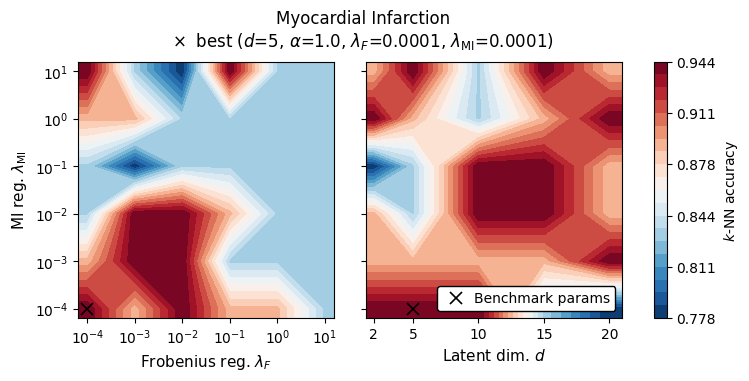

In [5]:
# 1x2 panel: MI reg. λ_MI vs Frobenius reg. λ_F and latent dim. d (exclude alpha)
panels_1x2 = [
    ("reg",     "mi_reg", {"n_comps": best["n_comps"], "alpha": best["alpha"], "reg_type": "fro"}),
    ("n_comps", "mi_reg", {"alpha": best["alpha"],     "reg": best["reg"],     "reg_type": "fro"}),
]
x_labels_1x2 = [r"Frobenius reg. $\lambda_F$", r"Latent dim. $d$"]

# Pre-compute grids and shared colormap range
grids_1x2 = []
for x_param, y_param, fixed in panels_1x2:
    grid = _dict_to_grid(sweep_df, x=x_param, y=y_param, fixed_params=fixed, col_val=value_col)
    grids_1x2.append(grid)

vmin_1x2 = min(g.to_numpy().min() for g in grids_1x2)
vmax_1x2 = max(g.to_numpy().max() for g in grids_1x2)
levels_1x2 = np.linspace(vmin_1x2, vmax_1x2, 21)
colorbar_ticks_1x2 = np.linspace(vmin_1x2, vmax_1x2, 6)
benchmark_handle = Line2D([0], [0], marker="x", linestyle="None", color="black", markersize=8, markeredgewidth=1.2, label="Benchmark params")

fig = plt.figure(figsize=(7.6, 3.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.18)
axes = [fig.add_subplot(gs[0, i]) for i in range(2)]
cax = fig.add_subplot(gs[0, 2])

for idx, (x_param, y_param, fixed) in enumerate(panels_1x2):
    ax = axes[idx]
    grid = grids_1x2[idx]
    X = np.asarray(grid.columns, dtype=float)
    Y = np.asarray(grid.index, dtype=float)
    Z = grid.to_numpy()

    x_log = x_param in {"reg", "mi_reg", "alpha"}
    y_log = y_param in {"reg", "mi_reg", "alpha"}

    Xp = _pad_axis_for_contour(X, x_log)
    Yp = _pad_axis_for_contour(Y, y_log)
    Z_pad = np.pad(Z, ((1, 1), (1, 1)), "edge")

    cntr = ax.contourf(Xp, Yp, Z_pad, levels=levels_1x2, cmap="RdBu_r", corner_mask=True)

    ax.set_xticks(np.log10(X) if x_log else X)
    ax.set_yticks(np.log10(Y) if y_log else Y)

    fmt_log = ticker.FuncFormatter(lambda v, _: r"$10^{{{:g}}}$".format(v))
    if x_log:
        ax.xaxis.set_major_formatter(fmt_log)
    if y_log:
        ax.yaxis.set_major_formatter(fmt_log)

    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)

    best_x = best.get(x_param)
    best_y = best.get(y_param)
    if best_x is not None and best_y is not None:
        bx = np.log10(best_x) if x_log else best_x
        by = np.log10(best_y) if y_log else best_y
        ax.plot(bx, by, "x", color="black", markersize=8, markeredgewidth=1.2, zorder=5, clip_on=False)

    ax.set_xlabel(x_labels_1x2[idx], fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"MI reg. $\lambda_{\mathrm{MI}}$", fontsize=11)
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", labelleft=False)

cbar = fig.colorbar(cntr, cax=cax, label="$k$-NN accuracy", ticks=colorbar_ticks_1x2, format="%.3f")
ref_pos = axes[0].get_position()
cax_pos = cax.get_position()
cax.set_position([cax_pos.x0, ref_pos.y0, cax_pos.width, ref_pos.height])
axes[1].legend(handles=[benchmark_handle], loc="lower right", frameon=True, facecolor="white", edgecolor="black", framealpha=1.0, handletextpad=0.25)

best_str_1x2 = ", ".join(f"{param_labels[k]}={best[k]}" for k in ["n_comps", "alpha", "reg", "mi_reg"])
if include_title:
    fig.suptitle(
        f"{dataset_name.replace('_', ' ').title()}\n"
        r"$\times\;$" f" best ({best_str_1x2})",
        fontsize=12,
        y=0.97,
    )

fig.savefig(save_dir / "contour_1x2_mi_reg_sensitivity.pdf", bbox_inches="tight", dpi=300)
print(f"Saved: {save_dir / 'contour_1x2_mi_reg_sensitivity.pdf'}")
plt.show()